In [1]:
import os
import glob
import datetime
import numpy as np
from scipy import stats
from scipy.stats import ttest_ind
import statsmodels.stats.multitest as smm
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import plotnine as p9


# Figure 2

Growth, pressure, and deamination curves

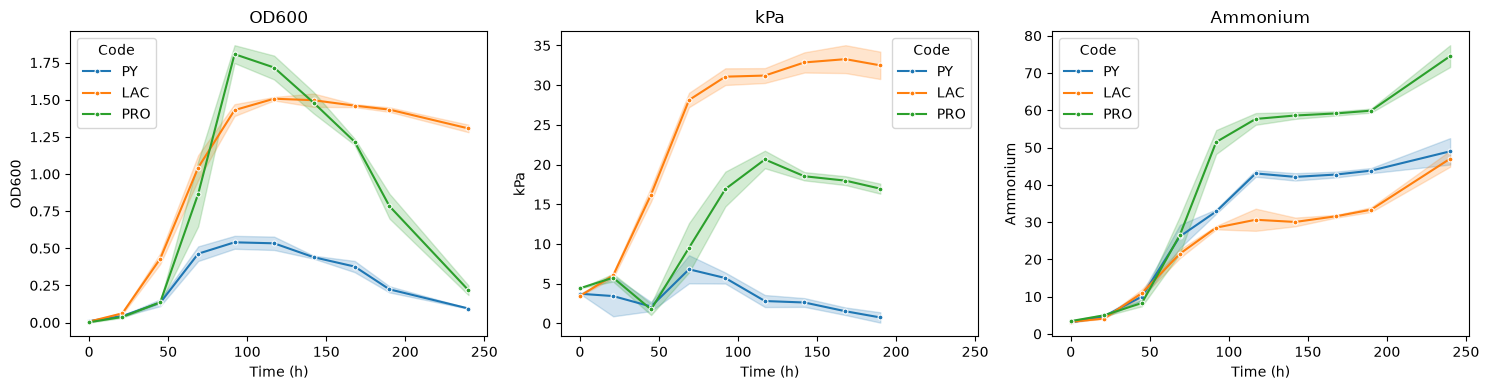

In [ ]:
data = pd.read_excel("Figure2.xlsx", sheet_name='Semilong_replicates')
df = data[(data["Code"]=="PY") | (data["Code"]=="LAC") | (data["Code"]=="PRO")]

variables = ["OD600", "kPa", "Ammonium"]

fig, axes = plt.subplots(1, len(variables), figsize=(15, 4), sharex=True)
for ax, var in zip(axes, variables):
    sns.lineplot(
        data=df, x="Time (h)", y=var, hue="Code",
        errorbar="sd",     # mean ± SD
        marker=".", markersize=7, ax=ax
    )
    ax.set_title(var)

plt.tight_layout()
plt.show()

Endpoint metabolite profiles

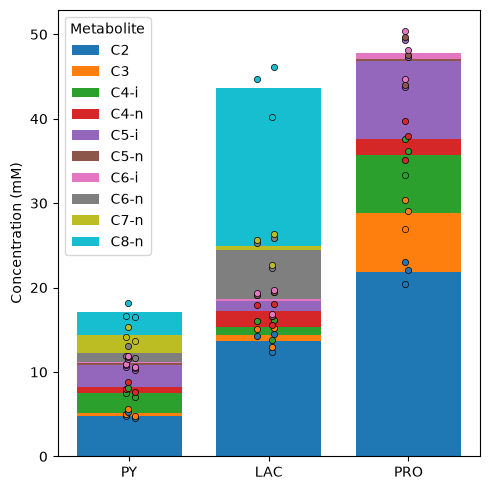

In [3]:
metabolites = ["C2", "C3", "C4-i", "C4-n", "C5-i", "C5-n", "C6-i", "C6-n", "C7-n", "C8-n"]
df_final = df[df["Time (h)"] == df["Time (h)"].max()]
groups = df_final["Code"].unique()
x_pos = {g: i for i, g in enumerate(groups)}

# purge any metabolites from the list that are 0 across all 3 sample sets 
active_metabolites = [m for m in metabolites if df_final[m].fillna(0).sum() > 0]
colors = cm.tab10(np.linspace(0, 1, len(active_metabolites)))

fig, ax = plt.subplots(figsize=(5, 5))
bar_width, jitter_width = 0.75, 0.09

for g in groups:
    sub = df_final[df_final["Code"] == g]
    x = x_pos[g]

    # avg as stacked bars
    means = sub[active_metabolites].mean()
    bottom = 0
    for metabolite, color in zip(active_metabolites, colors):
        val = means[metabolite] if pd.notna(means[metabolite]) else 0
        if val > 0:
            ax.bar(x, val, bottom=bottom, width=bar_width,
                   color=color, edgecolor="none",
                   label=metabolite if x == 0 else None)
        bottom += val

    # reps as stacked points
    for _, row in sub.iterrows():
        jitter = np.random.uniform(-jitter_width, jitter_width)  # locked jitter per replicate
        bottom = 0
        for metabolite, color in zip(active_metabolites, colors):
            val = row[metabolite] if pd.notna(row[metabolite]) else 0
            top = bottom + val
            if val > 0:  # don't plot zeroes
                ax.scatter(x + jitter, top, color=color, edgecolor="black",
                           linewidth=0.5, s=20, zorder=3)
            bottom = top

ax.set_xticks(list(x_pos.values()))
ax.set_xticklabels(list(x_pos.keys()))
ax.set_ylabel("Concentration (mM)")
ax.legend(title="Metabolite", loc="upper left")
plt.tight_layout()
plt.show()

Metabolite profiles over time

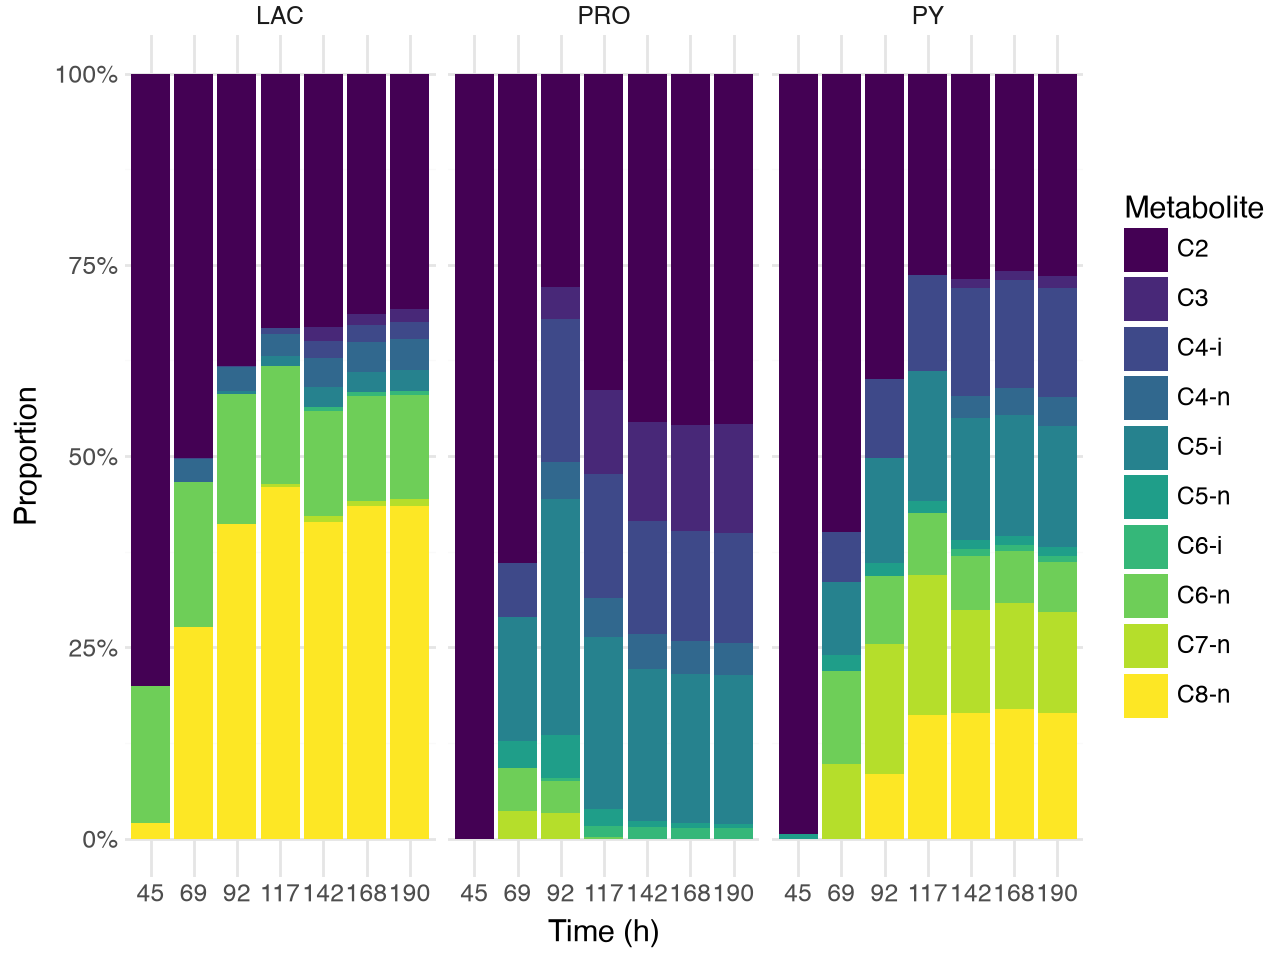

In [6]:
df_time = df[(df["Time (h)"] >= 45) & (df["Time (h)"] < 200)]

long_df = df_time.melt(id_vars=["Code", "Time (h)"], value_vars=active_metabolites,
                   var_name="Metabolite", value_name="Value")

# mean across replicates first
mean_df = (long_df.groupby(["Code", "Time (h)", "Metabolite"], observed=True)["Value"]
           .mean().reset_index())
mean_df["Metabolite"] = pd.Categorical(mean_df["Metabolite"], categories=active_metabolites, ordered=True)

mean_df["Time_h"] = pd.Categorical(mean_df["Time (h)"].astype(str),
                                    categories=[str(t) for t in sorted(mean_df["Time (h)"].unique())],
                                    ordered=True)

p = (
    p9.ggplot(mean_df, p9.aes(x="Time_h", y="Value", fill="Metabolite"))
    + p9.geom_bar(stat="identity", position="fill")  
    + p9.facet_wrap(f"~Code")
    + p9.scale_y_continuous(labels=lambda l: [f"{v*100:.0f}%" for v in l])
    + p9.labs(x="Time (h)", y="Proportion")
    + p9.theme_minimal()
)
p

Weight metabolites by C2 units

In [7]:
long_df = df.melt(id_vars=["Code", "Time (h)"], value_vars=active_metabolites,
                   var_name="Metabolite", value_name="Value")

metabolites = ["C2", "C3", "C4-i", "C4-n", "C5-i", "C5-n", "C6-i", "C6-n", "C7-n", "C8-n"]
weights =     [1, 0, 0, 2, 0, 1, 1, 3, 2, 4]
map = dict(zip(metabolites, weights))

mean_df = (long_df.groupby(["Code", "Time (h)", "Metabolite"], observed=True)["Value"]
           .mean().reset_index())
mean_df["Metabolite"] = pd.Categorical(mean_df["Metabolite"], categories=active_metabolites, ordered=True)

mean_df["Time_h"] = pd.Categorical(mean_df["Time (h)"].astype(str),
                                    categories=[str(t) for t in sorted(mean_df["Time (h)"].unique())],
                                    ordered=True)

weighted_df = mean_df.copy(deep=True)
weighted_df["Weight"] = weighted_df["Metabolite"].map(map)
weighted_df["Value"] = weighted_df["Value"] * weighted_df["Weight"]

products = (
    weighted_df.groupby(["Code", "Time (h)"], as_index=False)["Value"]
    .sum()
    .rename(columns={"Value": "Sum"})
)

/Users/blindner/.venvs/notebook-env/lib/python3.13/site-packages/plotnine/layer.py:358: PlotnineWarning: position_stack : Removed 21 rows containing missing values.


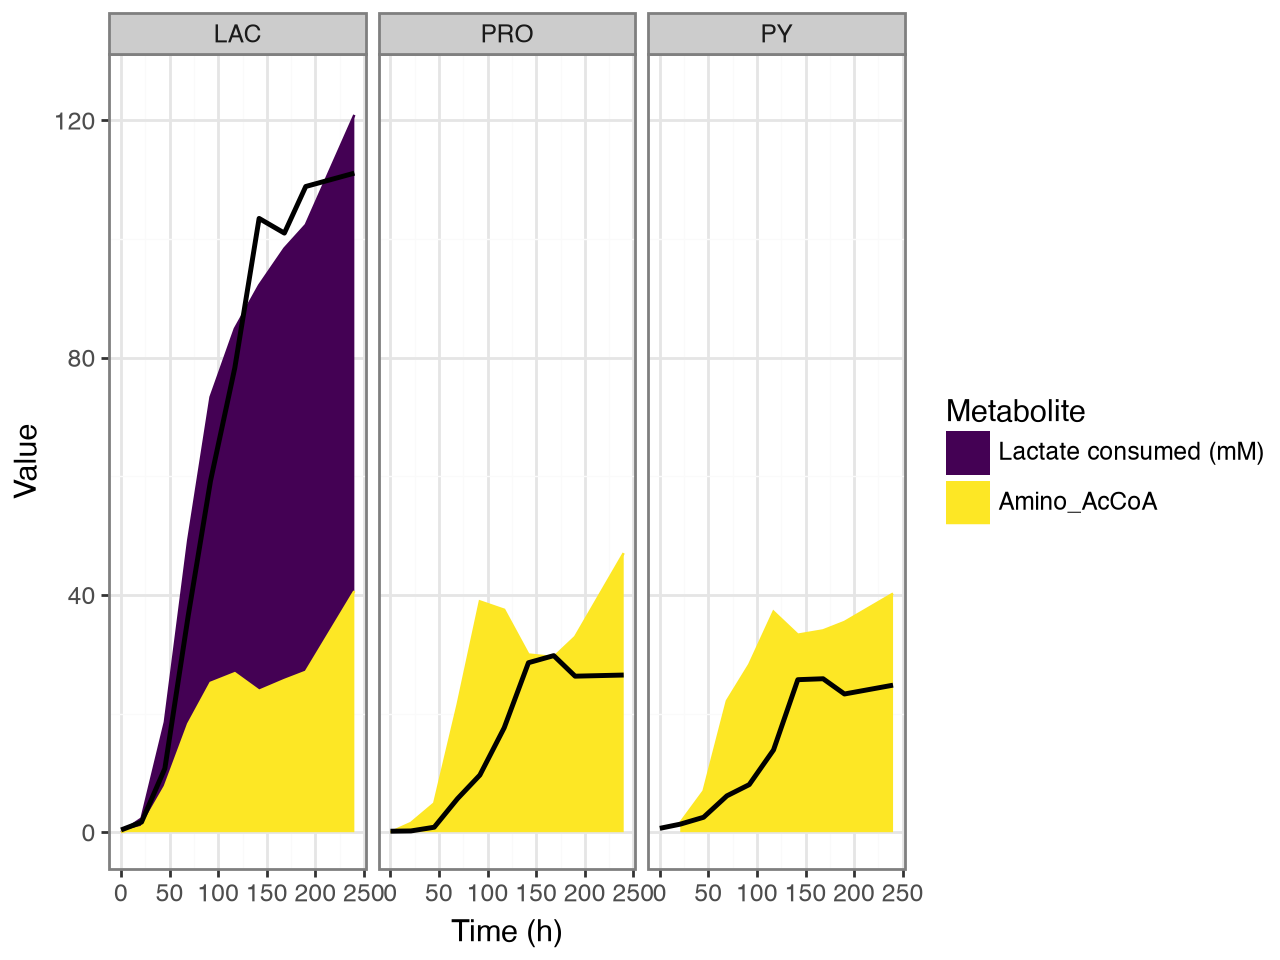

In [8]:
long_df = df.melt(id_vars=["Code", "Time (h)"], value_vars=["Lactate consumed (mM)", "Amino_AcCoA"],
                   var_name="Metabolite", value_name="Value")

reactants = (long_df.groupby(["Code", "Time (h)", "Metabolite"], observed=True)["Value"]
           .mean().reset_index())
reactants["Metabolite"] = pd.Categorical(reactants["Metabolite"], categories=["Lactate consumed (mM)", "Amino_AcCoA"], ordered=True)

p = (
    p9.ggplot() 
    + p9.geom_area(reactants, p9.aes(x="Time (h)",y="Value", colour="Metabolite",fill="Metabolite"), stat="identity")  
    + p9.geom_line(products, p9.aes(x="Time (h)",y="Sum"), size=1) 
    + p9.facet_wrap("~Code", nrow=1, scales="fixed")
    + p9.ylim(0,125)
    + p9.scale_fill_cmap_d(cmap_name='viridis')
    + p9.scale_color_cmap_d(cmap_name='viridis')
    + p9.theme_bw()
)
p

Endpoint glutamate and 5-AV

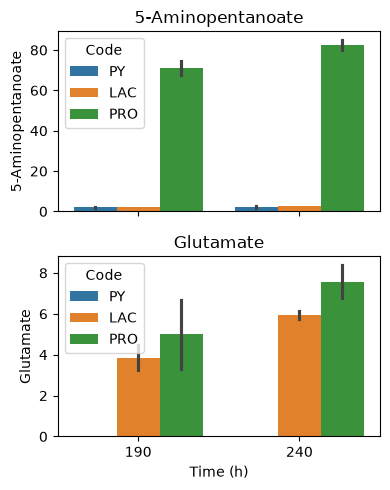

In [9]:
variables = ["5-Aminopentanoate", "Glutamate"]

fig, axes = plt.subplots(len(variables), 1, figsize=(4, 5), sharex=True)
for ax, var in zip(axes, variables):
    sns.barplot(
        data=df[df["Time (h)"]>168], x="Time (h)", y=var, hue="Code",
        errorbar="sd",
        ax=ax
    )
    ax.set_title(var)

plt.tight_layout()

The proteomics procedure and volcano plots are contained in a separate notebook in the `Figure2/` directory. 